# How good is the propagation model?

The project has a model now, so it needs an honest account of what it can and cannot do. This
notebook holds data out, measures the error, and reports where the model is worth trusting.

The short version: predicting how a delay carries along a route works well and beats the obvious
baseline by half. Predicting whether tomorrow will be delayed does not work at all, and that is
worth stating rather than quietly not attempting.

In [1]:
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))
import propagation as prop
import style

style.use()
P = Path.cwd().parent / "data" / "processed"
con = duckdb.connect()
con.execute("SET threads = 6")
con.execute("SET memory_limit = '10GB'")
print(f"{prop.POOLING=}")

prop.POOLING=('leg', 'line', 'global')


## 1. Holding data out

The model is fitted on legs up to the end of January and tested on February, so nothing it is
scored on was used to fit it. Splitting by time rather than at random matters here: a random
split would put the same trip's neighbouring days on both sides and flatter the result.

In [2]:
def legs_between(start, end):
    return con.execute(f'''
        WITH seq AS (
            SELECT trip_id, service_day, line, bpuic, station, arr_sched, arr_delay_s,
                   row_number() OVER (PARTITION BY trip_id, service_day
                                      ORDER BY arr_sched) AS pos
            FROM read_parquet('{P}/stops/*/*.parquet')
            WHERE arr_measured AND NOT cancelled AND arr_sched IS NOT NULL
              AND line IS NOT NULL AND bpuic BETWEEN 8500000 AND 8599999
              AND service_day >= DATE '{start}' AND service_day < DATE '{end}'
        )
        SELECT a.line, a.bpuic AS from_stop, b.bpuic AS to_stop,
               a.station AS from_name, b.station AS to_name,
               a.arr_delay_s::DOUBLE AS x, b.arr_delay_s::DOUBLE AS y,
               date_diff('minute', a.arr_sched, b.arr_sched) AS booked_min
        FROM seq a JOIN seq b
          ON a.trip_id = b.trip_id AND a.service_day = b.service_day AND b.pos = a.pos + 1
        WHERE date_diff('minute', a.arr_sched, b.arr_sched) BETWEEN 1 AND 60
    ''').df()


train_raw = legs_between("2025-09-01", "2026-02-01")
test = legs_between("2026-02-01", "2026-03-01")
print(f"fitted on {len(train_raw):,} legs to 31 January")
print(f"tested on {len(test):,} legs in February")

fitted on 18,797,078 legs to 31 January
tested on 3,492,560 legs in February


In [3]:
keys = ["line", "from_stop", "to_stop"]
train = (
    train_raw.assign(xy=train_raw.x * train_raw.y, xx=train_raw.x ** 2, yy=train_raw.y ** 2)
    .groupby(keys, as_index=False)
    .agg(n=("x", "size"), sx=("x", "sum"), sy=("y", "sum"),
         sxy=("xy", "sum"), sxx=("xx", "sum"), syy=("yy", "sum"),
         booked_min=("booked_min", "median"))
)
train["condition"] = "all"
print(f"{len(train):,} legs carry a fit")

10,834 legs carry a fit


## 2. One step ahead

How well can the delay at the next stop be predicted from the delay at this one? Three
baselines worth beating: assume no delay, assume it stays the same, and one global fitted line.

In [4]:
def mae(truth, pred):
    return float(np.mean(np.abs(truth - pred)))


fitted = prop.fit(train, prop.Params(pooling="leg", min_obs=60, conditioned=False))
joined = test.merge(fitted.reset_index(), on=keys, how="left")
covered = joined["a"].notna()
pred = np.where(covered, joined["a"] * joined["x"] + joined["b"], joined["x"])

rows = {
    "always zero": mae(test.y, 0.0),
    "it stays the same": mae(test.y, test.x),
    "one global line": None,
    "a coefficient per leg": mae(joined.y, pred),
}
glob = prop.fit(train, prop.Params(pooling="global", conditioned=False)).iloc[0]
rows["one global line"] = mae(test.y, glob["a"] * test.x + glob["b"])

out = pd.Series(rows).sort_values(ascending=False).round(1)
print(out.to_string(), "   seconds, mean absolute error")
better = 100 * (1 - rows["a coefficient per leg"] / rows["it stays the same"])
print()
print(f"the per leg model is {better:.0f}% better than assuming no change")
print(f"legs covered by their own fit: {100 * covered.mean():.1f}%")

always zero              68.3
it stays the same        43.4
one global line          41.9
a coefficient per leg    22.2    seconds, mean absolute error

the per leg model is 49% better than assuming no change
legs covered by their own fit: 99.3%


## 3. Does pooling help or hurt?

Pooling is the control the user holds, so it should be measured rather than asserted. Per leg is
the most faithful and the noisiest, global is the steadiest and the crudest.

In [5]:
scores = []
for pooling in prop.POOLING:
    for min_obs in (10, 60, 200, 1000):
        if pooling != "leg" and min_obs != 60:
            continue
        coef = prop.fit(train, prop.Params(pooling=pooling, min_obs=min_obs, conditioned=False))
        j = test.merge(coef.reset_index(), on=keys, how="left")
        p = np.where(j["a"].notna(), j["a"] * j["x"] + j["b"], j["x"])
        scores.append({"pooling": pooling, "min_obs": min_obs, "mae_s": round(mae(j.y, p), 1)})
pd.DataFrame(scores)

,pooling,min_obs,mae_s
0,leg,10,22.2
1,leg,60,22.2
2,leg,200,22.4
3,leg,1000,23.4
4,line,60,41.3
5,global,60,41.9


Pooling is the control that matters. Per leg is nearly twice as good as either alternative,
22 seconds against 41, because a leg's own slack is most of what determines how much delay it
sheds and pooling averages that away.

The minimum observations control, by contrast, barely moves anything: 22.2 seconds at ten
observations and 23.4 at a thousand. That is worth saying rather than implying it earns its
place. It guards against a wild coefficient on a thin leg, which is a real risk and visible in
individual legs, but it does not change the error over the whole test set. If the evaluation
shows nobody uses it, that would be a reason to drop it rather than defend it.

## 4. Where the model is worth trusting

A coefficient fitted on a handful of observations is not worth much. This is the argument for
the minimum observations control, and for showing the user which level a prediction came from.

In [6]:
bucket = pd.cut(joined["n"], [0, 30, 100, 300, 1000, 10**9],
                labels=["<30", "30-100", "100-300", "300-1000", "1000+"])
by_evidence = (
    joined.assign(bucket=bucket, err=np.abs(joined.y - pred))
    .groupby("bucket", observed=True)
    .agg(legs=("err", "size"), mae_s=("err", "mean"))
    .round(1)
)
print(by_evidence.to_string())

             legs  mae_s
bucket                  
30-100       9156   28.4
100-300     48359   31.4
300-1000   150339   35.5
1000+     3260428   21.3


This table looks wrong at first and is worth reading carefully. The error rises from 28 seconds
in the 30 to 100 bucket to 36 in the 300 to 1000 bucket, then falls to 21 for the largest.
More data appears to make the model worse, which cannot be right.

It is a confound, not a finding about sample size. The buckets hold different kinds of leg. A
leg with thousands of observations is a city S-Bahn section running every few minutes, where
delays are small and regular and therefore easy to predict. A leg with a few hundred is a
regional line with sparser, more variable service. What the table really shows is that busy
urban legs are more predictable than quiet rural ones, and the observation count is standing in
for that.

Comparing error across these buckets says nothing about whether fitting on more data helps. To
answer that I would have to hold the leg fixed and vary how much of its history was used.

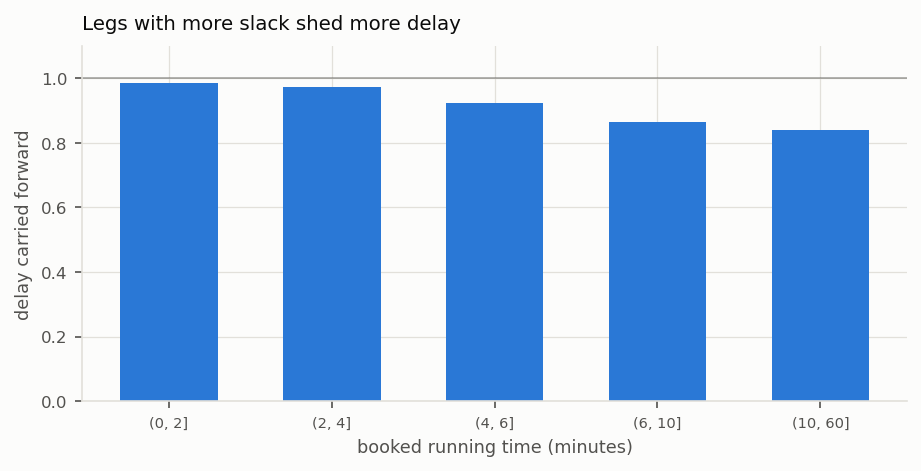

            median  size
booked_min              
(0, 2]       0.984  1753
(2, 4]       0.974  3440
(4, 6]       0.923  1906
(6, 10]      0.863  1588
(10, 60]     0.839  2147


In [7]:
fitted_all = prop.fit(train, prop.Params(pooling="leg", min_obs=60, conditioned=False))
look = fitted_all.reset_index().merge(train[keys + ["booked_min"]], on=keys)
band = pd.cut(look["booked_min"], [0, 2, 4, 6, 10, 60])
slack = look.groupby(band, observed=True)["a"].agg(["median", "size"]).round(3)

fig, ax = plt.subplots(figsize=(6.2, 3.2))
ax.bar(range(len(slack)), slack["median"], color=style.SERIES[0], width=0.6)
ax.axhline(1.0, color=style.INK_SOFT, linewidth=0.8, alpha=0.5)
ax.set_xticks(range(len(slack)))
ax.set_xticklabels([str(i) for i in slack.index], fontsize=7)
ax.set_xlabel("booked running time (minutes)")
ax.set_ylabel("delay carried forward")
ax.set_title("Legs with more slack shed more delay")
ax.set_ylim(0, 1.1)
fig.tight_layout()
fig.savefig(Path.cwd().parent / "figures" / "before" / "06_recovery_by_slack.png")
plt.show()
print(slack.to_string())

The model recovers something physical. A leg booked two minutes has no room to make up time and
keeps almost everything, while one booked ten minutes sheds a quarter. Nobody told it about
timetable padding; it is in the data.

## 5. What the model cannot do

Predicting tomorrow's delay. Worth measuring so the limit is on the record rather than implied.

In [8]:
daily = con.execute(f'''
    SELECT line, hour::DATE AS day, median(median_delay_s) AS delay_s
    FROM read_parquet('{P}/cells.parquet')
    WHERE median_delay_s IS NOT NULL AND line IS NOT NULL
    GROUP BY line, day HAVING sum(n_trips) > 200
''').df()
daily["day"] = pd.to_datetime(daily["day"])

errs = []
for _, grp in daily.sort_values("day").groupby("line"):
    s = grp.set_index("day")["delay_s"].asfreq("D")
    if s.notna().sum() < 250:
        continue
    hist, test_days = s.iloc[:-56], s.iloc[-56:]
    seasonal = hist.groupby(hist.index.dayofweek).median()
    for stamp, truth in test_days.dropna().items():
        errs.append({
            "yesterday": abs(truth - s.shift(1).get(stamp, np.nan)),
            "same day last week": abs(truth - s.shift(7).get(stamp, np.nan)),
            "seasonal median": abs(truth - seasonal.get(stamp.dayofweek, np.nan)),
            "always zero": abs(truth),
        })
print((pd.DataFrame(errs).mean() / 60).round(3).sort_values().to_string(),
      "   minutes, mean absolute error")

yesterday             0.187
same day last week    0.194
seasonal median       0.204
always zero           0.591    minutes, mean absolute error


Three of the four are tied to within a hundredth of a minute. There is no model to build here:
the predictable part of delay is the timetable, and what is left is incidents, which are not
predictable by definition.

This is why the tool asks "how far will this delay reach" rather than "will tomorrow be bad".
The first question has an answer in the data. The second does not.

## What I would check next

- Whether conditioning on peak and off peak earns its place, measured the same way.
- Whether a leg's coefficient drifts across the year, which would argue for a trailing fit
  rather than one over the whole period.
- Whether the compounding interval is calibrated, that is, whether roughly 95% of observed
  delays actually fall inside the 1.96 sigma band.